# E4: tetos econômicos e cenários para o custo do atraso

Os ganhos desta etapa são **cenários condicionais**, não uma medição de benefício em milissegundos. O backtest observa atrasos de 1 a 30 minutos. E4 combina seus parâmetros com tempos de E1 e contagens de E3; para N > 64, mantém os parâmetros de N = 64, uma limitação explícita.

As saídas centrais são o requisito de throughput médio $r^*=T_q/\tau_c$ e o teto $X_{\max}=C_c+(V/10^6)L(\tau_c)/390$. A relação $T_q/r$ é um cenário de capacidade de fornecimento de portas T; o tempo físico, com profundidade e fábricas em paralelo, é estimado separadamente em E3. $X_{\max}$ supõe tempo quântico nulo. Os 390 recálculos por pregão são uma frequência desejada, viável somente quando o cálculo termina em até 60 segundos.

O preço de US$1,60/s é tratado apenas como **meta hipotética**, sem supor que um preço comercial de hardware sem correção de erros valha para hardware tolerante a falhas. O nome `r_meta_preco` substitui `r_IBM`.

A taxa-meta é o ínfimo das taxas r >= r* que atingem o preço-meta. O código mantém um limite superior factível por bisseção monotônica. Como o cenário degrau é descontínuo, o preço obtido nessa taxa pode ultrapassar a meta em um salto; não se exige igualdade de preços. Os dois limites e seus preços são exportados para conferência.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

RAIZ = Path.cwd().resolve()
if RAIZ.name == "codigo":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "codigo"))
from cenarios_atraso import gerar_saidas, PRECO_META_S
from figuras_artigo import gerar_figuras

base, cenarios = gerar_saidas(RAIZ)
print("Todos os resultados econômicos são condicionais à forma de L e à transferência do proxy E2.")
print(f"Preço-meta hipotético, sem previsão de preço de hardware: US${PRECO_META_S:.2f}/s.")
display(base[["N", "eps", "carga", "tau_c_s", "r_estrela", "X_max", "p_T_max"]])

Todos os resultados econômicos são condicionais à forma de L e à transferência do proxy E2.
Preço-meta hipotético, sem previsão de preço de hardware: US$1.60/s.


,N,eps,carga,tau_c_s,r_estrela,X_max,p_T_max
0,1,0.010,cholesky,0.000430,1.593641e+13,0.025638,3.745267e-12
5,1,0.010,fator unico,0.000430,3.020056e+13,0.025638,1.976324e-12
10,1,0.001,cholesky,0.004501,1.565245e+14,0.128656,1.825998e-13
15,1,0.001,fator unico,0.004501,2.976625e+14,0.128656,9.601932e-14
20,2,0.010,cholesky,0.004060,3.506409e+12,0.135592,9.524950e-12
25,2,0.010,fator unico,0.004060,5.052627e+12,0.135592,6.610101e-12
30,2,0.001,cholesky,0.067849,2.313329e+13,0.893463,5.692367e-13
35,2,0.001,fator unico,0.067849,3.352625e+13,0.893463,3.927762e-13
40,4,0.010,cholesky,0.015741,1.977169e+12,0.278748,8.956534e-12
45,4,0.010,fator unico,0.015741,2.354342e+12,0.278748,7.521671e-12


## Sensibilidade à forma de L

O código em `cenarios_atraso.py` compara as cinco formas solicitadas na avaliação. Todas têm $L(0)=0$ e a mesma âncora $A=c\,60^\beta$, o valor da lei ajustada a um minuto:

- potência ajustada: $L(d)=cd^\beta$;
- potência com $\beta=0,5$: $L(d)=A(d/60)^{0,5}$;
- potência linear: $L(d)=Ad/60$;
- degrau: $L(d)=A\lfloor d/60\rfloor^\beta$, sem custo abaixo de 60 s;
- exponencial saturante: $L(d)=A(1-e^{-d/s})/(1-e^{-60/s})$.

Na exponencial, a escala $s$ também faz coincidir o valor da potência ajustada em 1.800 s: a razão das duas âncoras é $30^\beta$. É uma calibração entre pontos do intervalo observado, sem dados abaixo de um minuto. As formas alternativas não são apresentadas como ajustes validados nessa região. Os parâmetros e as âncoras são exportados em `dados/calibracao_formas_L.csv`.

No degrau, se $\tau_c<60$ s, a antecipação abaixo de um minuto tem valor econômico nulo; nesse cenário o teto $X_{\max}$ se reduz ao custo clássico. Isso mostra por que os ganhos da lei de potência não podem ser apresentados como benefício comprovado.

In [2]:
selecao = cenarios[(cenarios.N == 64) & (cenarios.eps == 0.01)
                   & (cenarios.carga == "fator unico")]
display(selecao[["forma_L", "X_max", "ganho_anual_max_condicional", "r_meta_sobre_r_estrela"]])
print("Sensibilidades já existentes a carteira, medida do custo e tamanho da mesa:")
display(pd.read_csv(RAIZ / "dados/sensibilidade.csv"))

,forma_L,X_max,ganho_anual_max_condicional,r_meta_sobre_r_estrela
125,potencia_ajustada,1.878735,184640.621022,1.586546
126,potencia_05,6.308492,619997.135086,1.263619
127,potencia_1,0.604047,59364.253531,2.457013
128,degrau,0.000015,0.000000,57600.000000
129,exponencial,0.624752,61399.077269,2.408911


Sensibilidades já existentes a carteira, medida do custo e tamanho da mesa:


,N,caso,forma_L,natureza_resultado,limite_milhoes,C_c,teto_dR,X_max,cadencia_alvo_s,L_tau_c_fora_intervalo_medido,...,tau_q_s_1e+06,L_tau_q_fora_intervalo_medido_1e+06,X_1e+06,recalculo_1min_viavel_1e+06,termina_no_pregao_1e+06,tau_q_s_1e+08,L_tau_q_fora_intervalo_medido_1e+08,X_1e+08,recalculo_1min_viavel_1e+08,termina_no_pregao_1e+08
0,8,"perda media, mediana",potencia_ajustada,cenario_condicional,100.0,8.909039e-07,0.354519,0.354519,60,True,...,70604.09712,True,-13023.011218,False,False,706.040971,False,-473.064594,False,True
1,8,"ES 97,5%, mediana",potencia_ajustada,cenario_condicional,100.0,8.909039e-07,2.242567,2.242568,60,True,...,70604.09712,True,-183722.153255,False,False,706.040971,False,-5183.973028,False,True
2,8,carteira quartil 25%,potencia_ajustada,cenario_condicional,100.0,8.909039e-07,0.244540,0.244541,60,True,...,70604.09712,True,-13651.662088,False,False,706.040971,False,-434.669293,False,True
3,8,carteira quartil 75%,potencia_ajustada,cenario_condicional,100.0,8.909039e-07,0.544640,0.544641,60,True,...,70604.09712,True,-13221.556339,False,False,706.040971,False,-547.161536,False,True
4,8,limite US$ 1 milhoes,potencia_ajustada,cenario_condicional,1.0,8.909039e-07,0.003545,0.003546,60,True,...,70604.09712,True,-130.230111,False,False,706.040971,False,-4.730645,False,True
5,8,limite US$ 10 milhoes,potencia_ajustada,cenario_condicional,10.0,8.909039e-07,0.035452,0.035453,60,True,...,70604.09712,True,-1302.301121,False,False,706.040971,False,-47.306459,False,True
6,8,limite US$ 1000 milhoes,potencia_ajustada,cenario_condicional,1000.0,8.909039e-07,3.545185,3.545186,60,True,...,70604.09712,True,-130230.112189,False,False,706.040971,False,-4730.645950,False,True
7,32,"perda media, mediana",potencia_ajustada,cenario_condicional,100.0,7.310850e-06,1.252741,1.252748,60,True,...,244690.30628,True,-34350.818449,False,False,2446.903063,True,-1117.523253,False,True
8,32,"ES 97,5%, mediana",potencia_ajustada,cenario_condicional,100.0,7.310850e-06,6.714902,6.714909,60,True,...,244690.30628,True,-381876.327423,False,False,2446.903063,True,-9733.327175,False,True
9,32,carteira quartil 25%,potencia_ajustada,cenario_condicional,100.0,7.310850e-06,1.133020,1.133027,60,True,...,244690.30628,True,-34068.277674,False,False,2446.903063,True,-1074.685184,False,True


## Frequência de recálculo

Os arquivos de saída registram, para cada cenário de throughput, se uma execução termina em 60 segundos e se termina no pregão de 23.400 segundos. Os valores formais de X fora dessa capacidade não descrevem um serviço capaz de recalcular 390 vezes ao dia. A extrapolação para atrasos maiores que 30 minutos também está fora do intervalo observado.

In [3]:
colunas = ["N", "eps", "carga", "tau_q_s_1e+08",
           "recalculo_1min_viavel_1e+08", "termina_no_pregao_1e+08"]
display(base[(base.eps == 0.01) & (base.carga == "fator unico")][colunas])

,N,eps,carga,tau_q_s_1e+08,recalculo_1min_viavel_1e+08,termina_no_pregao_1e+08
5,1,0.01,fator unico,129.724094,False,True
25,2,0.01,fator unico,205.128266,False,True
45,4,0.01,fator unico,370.593070,False,True
65,8,0.01,fator unico,706.040971,False,True
85,16,0.01,fator unico,1275.661664,False,True
105,32,0.01,fator unico,2446.903063,False,True
125,64,0.01,fator unico,5064.831580,False,True
145,128,0.01,fator unico,10915.259500,False,True
165,256,0.01,fator unico,21497.872979,False,True
185,512,0.01,fator unico,38758.969664,False,False


## Duas figuras finais

`figuras_artigo.py` é a fonte única das figuras do artigo. A figura de r* compara Cholesky e fator único contra MC e QMC; o corte explícito do eixo separa os cenários de hardware das curvas relevantes. A figura de L mostra os dados medidos de N=64 e separa a região subminuto, sem observações, dos dados de 1 a 30 minutos. As antigas figuras redundantes não são recriadas. PDFs vetoriais e prévias PNG usam a fonte TeX Gyre Termes, compatível com Times no modelo IEEE, distribuída sob a licença GUST.

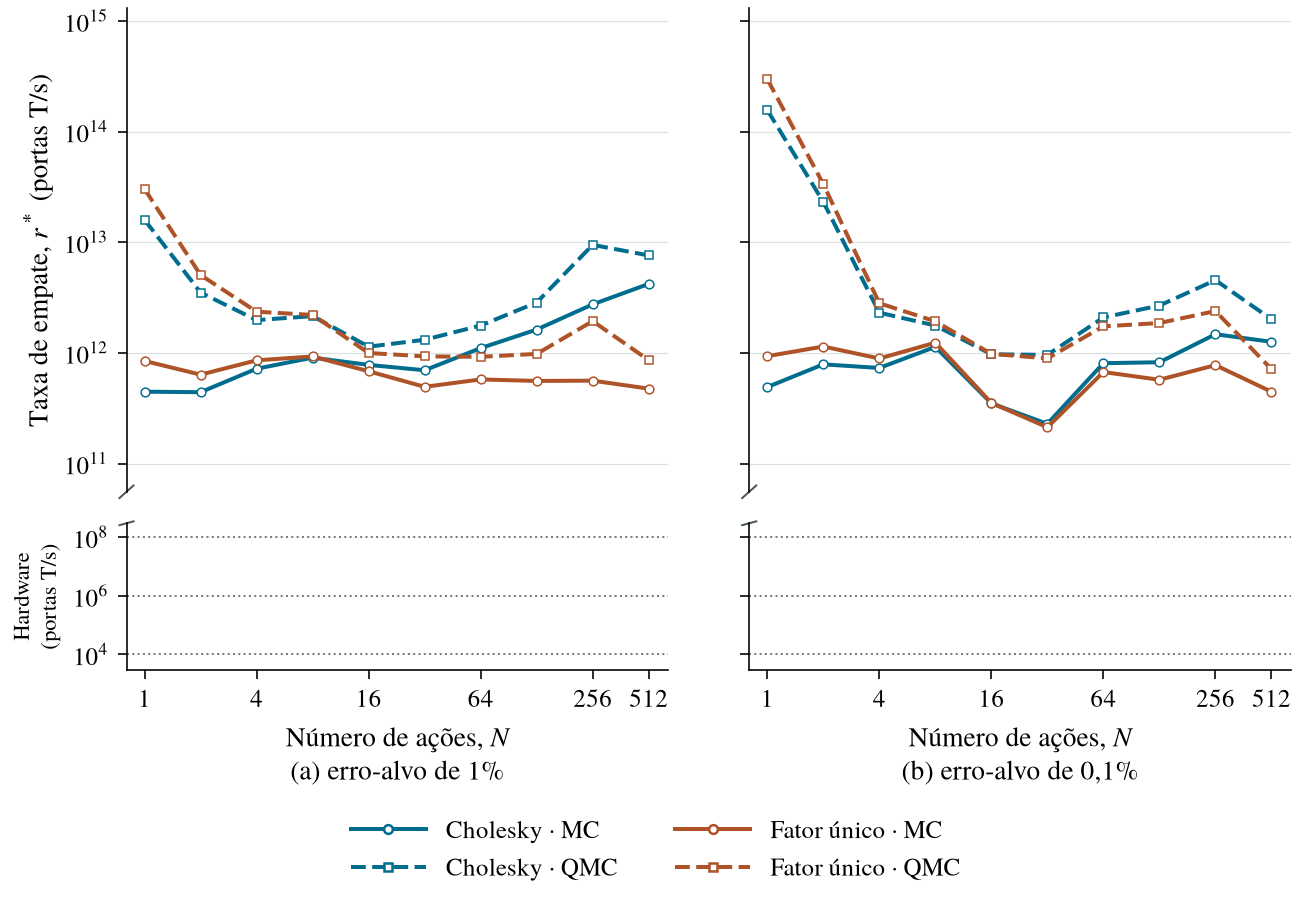

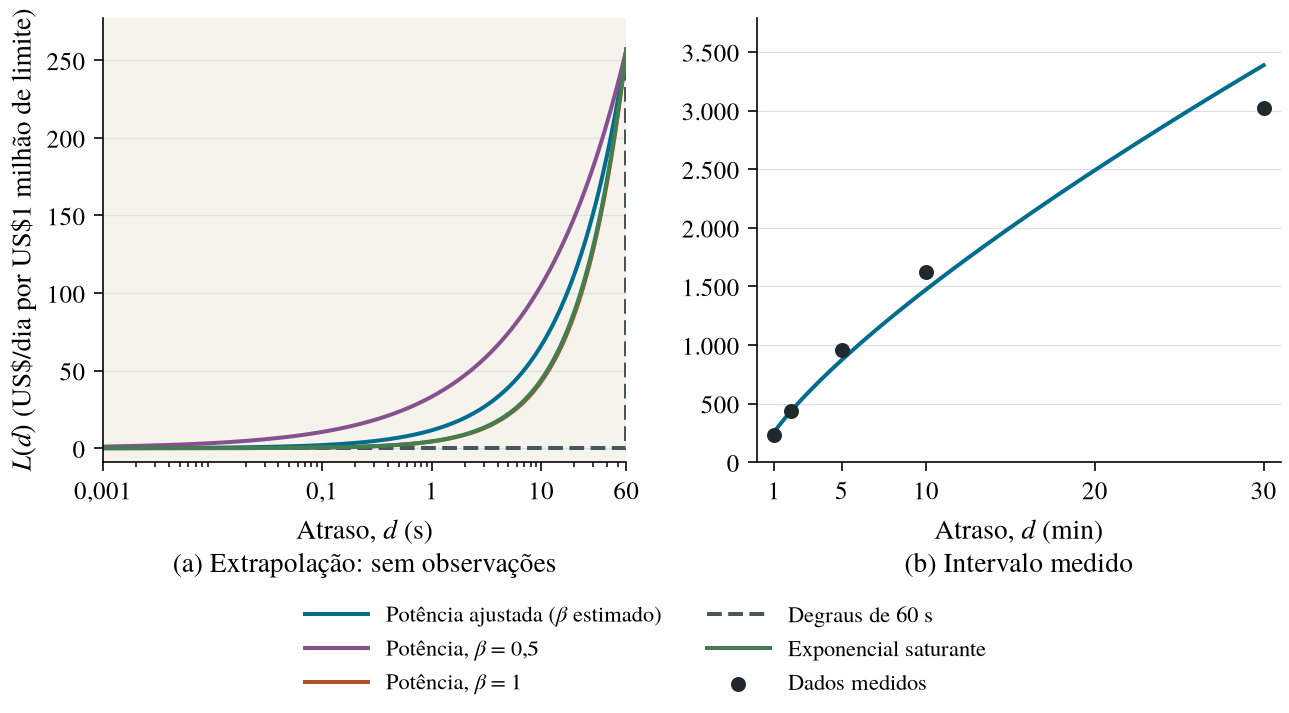

In [4]:
gerar_figuras(RAIZ)
for nome in ("taxa_empate", "custo_atraso"):
    display(Image(filename=str(RAIZ / "figuras" / f"{nome}.png")))